# Structured Products on JPMorgan Chase & Co. — Companion Notebook

This notebook reproduces every number and figure in the report *Design of Structured Products: JPMorgan Chase & Co* (`JPM_Structured_Products.pdf`). It can be read alongside the report or on its own.

We design two products on JPM stock that mature on **15 January 2027**:

1. **Partially Principal Protected Note (PPPN)**: 90% of the capital is guaranteed, and a premium is paid when the stock leaves a corridor around today's price.
2. **Airbag Note**: the investor gets back the full capital as long as the stock stays above an *airbag level*, and participates partially in any gains.

For each product we
* write down the payoff,
* replicate it with a zero-coupon bond and European options and price it with real market quotes, and
* estimate its expected performance with a Monte Carlo simulation of the stock.

**Contents**
1. Setup and market data
2. Product 1: PPPN
3. Product 2: Airbag Note
4. Summary

All data lives in `../data`, and the figures are written to `../report/figures`, where the LaTeX report picks them up.

## 1. Setup and market data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
FIGS = Path("../report/figures")
FIGS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 9,
    "figure.figsize": (5.5, 4.2),
    "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIGS / f"{name}.pdf")

### 1.1 Option chain

All quotes were taken from Yahoo Finance on **12 November 2025, 12:00 ET** ($t=0$). The file holds the European calls and puts on JPM that expire on 15 January 2027. There are fewer puts than calls because some strikes are not quoted for puts.

In [2]:
options = pd.read_csv(DATA / "jpm_options_2027-01-15.csv")
calls = options[options.type == "call"].set_index("strike")["price"]
puts = options[options.type == "put"].set_index("strike")["price"]

print(f"{len(calls)} calls, {len(puts)} puts, strikes from {options.strike.min()} to {options.strike.max()}")
options.pivot(index="strike", columns="type", values="price").T

47 calls, 41 puts, strikes from 105 to 470


strike,105,110,115,120,125,130,135,140,145,150,...,380,390,400,410,420,430,440,450,460,470
type,,,,,,,,,,,,,,,,,,,,,
call,205.95,191.90,172.92,178.00,168.06,182.71,162.75,174.67,160.80,162.25,...,13.70,12.33,11.50,9.7,7.95,6.05,5.5,3.88,3.9,3.25
put,0.52,0.56,0.97,1.05,0.96,1.05,1.40,1.21,1.34,1.58,...,86.14,NaN,106.79,116.6,NaN,NaN,NaN,NaN,NaN,170.14


### 1.2 Spot price, interest rate and maturity

* **Spot price**: the JPM price at $t=0$, $S_0 = 320.41$ USD.
* **Maturity**: from 12 November 2025 to 15 January 2027 is 14 months, so $T = 14/12$ years.
* **Risk-free rate**: the U.S. Treasury par yields for 1 and 2 years on 12 November 2025, linearly interpolated to 14 months. We assume $r$ is constant and use continuous compounding throughout.

In [3]:
S0 = 320.41
T = 14 / 12

yields = pd.read_csv(DATA / "us_treasury_par_yields_2025-11-12.csv")
y1, y2 = yields["1 Yr"].item() / 100, yields["2 Yr"].item() / 100
r = y1 + (T - 1) * (y2 - y1)
disc = np.exp(-r * T)

print(f"1y yield = {y1:.2%}, 2y yield = {y2:.2%}  ->  r = {r:.3%}")
print(f"T = {T:.3f},  discount factor e^(-rT) = {disc:.5f}")

1y yield = 3.65%, 2y yield = 3.56%  ->  r = 3.635%
T = 1.167,  discount factor e^(-rT) = 0.95848


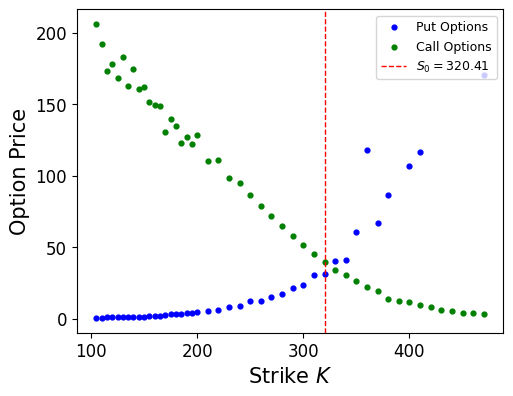

In [4]:
fig, ax = plt.subplots()
ax.scatter(puts.index, puts.values, s=12, color="blue", label="Put Options")
ax.scatter(calls.index, calls.values, s=12, color="green", label="Call Options")
ax.axvline(S0, color="red", ls="--", lw=1, label=f"$S_0 = {S0}$")
ax.set_xlabel("Strike $K$")
ax.set_ylabel("Option Price")
ax.legend()
save(fig, "option_prices")
plt.show()

A few quotes look stale (for example the deep in-the-money put at $K=360$, or the put at $K=250$, which is priced above the one at $K=260$). Neither product uses these strikes, so we keep the data unchanged.

### 1.3 Historical prices

We use five years of daily JPM prices up to $t=0$ for two things: to show the products' payoff regions against the stock's past behaviour, and to estimate the drift for the simulation. The charts use closing prices. The drift estimate uses dividend-adjusted closes, so dividends count towards the return.

In [5]:
hist = pd.read_csv(DATA / "jpm_prices_2020-11-12_2025-11-12.csv", parse_dates=["date"], index_col="date")
prices = hist["close"]
print(f"{len(prices)} trading days, last close = {hist['close'].iloc[-1]:.2f} (= S0)")

1256 trading days, last close = 320.41 (= S0)


## 2. Product 1: Partially Principal Protected Note (PPPN)

### 2.1 Payoff

The investor pays $N$ at $t=0$. At maturity the note pays $0.9N$, plus a premium if $S_T$ ends up outside the corridor $[K_1, K_2]$ with $K_1 < S_0 < K_2$:

$$
\text{Premium}(S_T) = \frac{N}{S_0}\Big[(K_1 - S_T)^+ + (S_T - K_2)^+\Big].
$$

Like the report, we set $N = S_0$ from here on, so the premium is just $(K_1-S_T)^+ + (S_T-K_2)^+$.

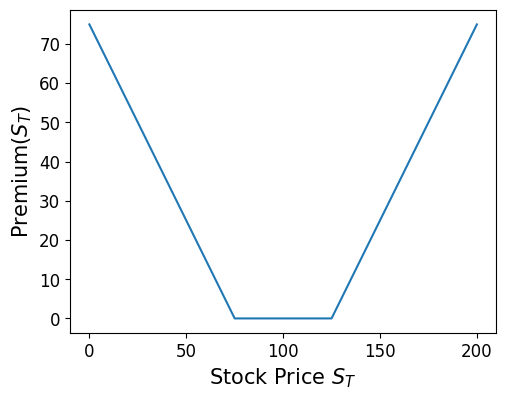

In [6]:
def pppn_premium(ST, K1, K2):
    return np.maximum(K1 - ST, 0) + np.maximum(ST - K2, 0)

s = np.linspace(0, 200, 401)
fig, ax = plt.subplots()
ax.plot(s, pppn_premium(s, 75, 125))
ax.set_xlabel("Stock Price $S_T$")
ax.set_ylabel(r"Premium$(S_T)$")
save(fig, "pppn_premium_payoff")
plt.show()

### 2.2 Replication

| Position | Value at $t=0$ | Value at $T$ |
|---|---|---|
| Zero-coupon bond | $0.9N e^{-rT}$ | $0.9N$ |
| $N/S_0$ long puts, strike $K_1$ | $\frac{N}{S_0}EP(K_1,T)$ | $\frac{N}{S_0}(K_1-S_T)^+$ |
| $N/S_0$ long calls, strike $K_2$ | $\frac{N}{S_0}EC(K_2,T)$ | $\frac{N}{S_0}(S_T-K_2)^+$ |
| Issuer margin $M = mN$ | $mN$ | — |

The total must equal the amount invested, $N$. This leaves the following budget for the options:

$$
EP(K_1,T) + EC(K_2,T) \le S_0\,(1 - 0.9e^{-rT} - m).
$$

Strikes only come in discrete steps, so we allow "$\le$". Any money left over goes to the issuer.

In [7]:
def option_budget(m):
    return S0 * (1 - 0.9 * disc - m)

for m in (0.001, 0.005, 0.01):
    print(f"m = {m:.1%}:  option budget = {option_budget(m):.2f}")

m = 0.1%:  option budget = 43.69
m = 0.5%:  option budget = 42.41
m = 1.0%:  option budget = 40.81


### 2.3 Choosing the strikes

We check every pair of a put strike below $S_0$ and a call strike above $S_0$. A pair is valid if it fits within the budget. Among the valid pairs we pick the one with the **narrowest corridor** $K_2-K_1$, because that gives the investor the best chance of a premium. If several pairs are equally narrow, we take the one that uses the most of the budget.

In [8]:
pairs = pd.DataFrame(
    [(K1, K2, puts[K1] + calls[K2]) for K1 in puts.index[puts.index < S0] for K2 in calls.index[calls.index > S0]],
    columns=["K1", "K2", "cost"],
)
pairs["width"] = pairs.K2 - pairs.K1

def best_pair(m):
    valid = pairs[pairs.cost <= option_budget(m)]
    return valid.sort_values(["width", "cost"], ascending=[True, False]).iloc[0]

for m in (0.001, 0.005, 0.01):
    b = best_pair(m)
    print(f"m = {m:.1%}:  K1 = {b.K1:.0f}, K2 = {b.K2:.0f}, corridor = {b.width:.0f}, cost = {b.cost:.2f}")

m = 0.1%:  K1 = 280, K2 = 350, corridor = 70, cost = 43.44
m = 0.5%:  K1 = 270, K2 = 350, corridor = 80, cost = 41.54
m = 1.0%:  K1 = 290, K2 = 370, corridor = 80, cost = 40.66


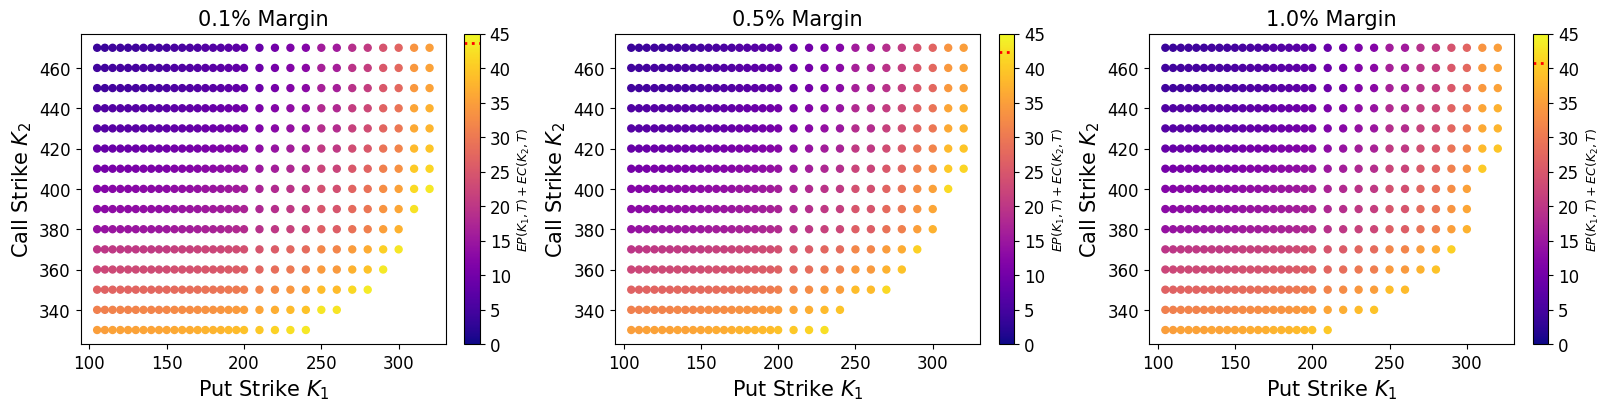

In [9]:
margins = (0.001, 0.005, 0.01)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
for ax, m in zip(axes, margins):
    budget = option_budget(m)
    valid = pairs[pairs.cost <= budget]
    sc = ax.scatter(valid.K1, valid.K2, c=valid.cost, cmap="plasma", vmin=0, vmax=45, s=25)
    cb = fig.colorbar(sc, ax=ax)
    cb.ax.axhline(budget, color="red", ls=":", lw=2)
    cb.set_label(r"$EP(K_1,T)+EC(K_2,T)$", fontsize=9)
    ax.set_title(f"{m:.1%} Margin")
    ax.set_xlabel("Put Strike $K_1$")
    ax.set_ylabel("Call Strike $K_2$")
save(fig, "pppn_valid_strikes")
plt.show()

We use a margin of $m = 0.5\%$ for the product. With this margin the narrowest valid corridor is 80 USD wide. Several pairs reach it, and $(K_1, K_2) = (270, 350)$ uses the most of the budget.

In [10]:
m_pppn = 0.005
K1, K2 = int(best_pair(m_pppn).K1), int(best_pair(m_pppn).K2)
option_cost = puts[K1] + calls[K2]
print(f"EP({K1}) + EC({K2}) = {puts[K1]:.2f} + {calls[K2]:.2f} = {option_cost:.2f} <= {option_budget(m_pppn):.2f}")

EP(270) + EC(350) = 15.45 + 26.09 = 41.54 <= 42.41


The chart below shows the selected corridor against the past five years of JPM prices.

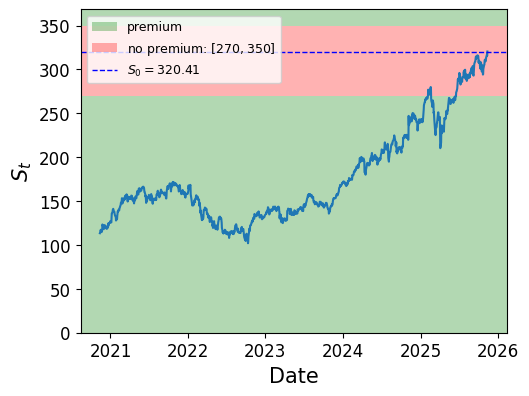

In [11]:
def shade(ax, lo, hi, color, label=None):
    ax.axhspan(lo, hi, color=color, alpha=0.3, lw=0, label=label)

top = 1.15 * prices.max()
fig, ax = plt.subplots()
shade(ax, 0, K1, "green", "premium")
shade(ax, K1, K2, "red", f"no premium: $[{K1}, {K2}]$")
shade(ax, K2, top, "green")
ax.plot(prices.index, prices.values)
ax.axhline(S0, color="blue", ls="--", lw=1, label=f"$S_0 = {S0}$")
ax.set_ylim(0, top)
ax.set_xlabel("Date")
ax.set_ylabel("$S_t$")
ax.legend(loc="upper left")
save(fig, "pppn_jpm_corridors")
plt.show()

### 2.4 Monte Carlo simulation

Pricing uses risk-neutral option quotes. To estimate how the product is likely to *perform*, however, we simulate the stock under the real-world measure. We model it as a geometric Brownian motion,

$$
dS_t = \mu S_t\,dt + \sigma S_t\,dW_t,
$$

and discretise it with the Euler–Maruyama scheme over the trading days up to maturity:

$$
S_{t+\Delta t} = S_t + \mu S_t \Delta t + \sigma S_t \sqrt{\Delta t}\,\varepsilon_t, \qquad \varepsilon_t \sim \mathcal N(0,1).
$$

**Parameters**
* $\mu$: the mean daily log-return of JPM over the past five years, annualised with 252 trading days.
* $\sigma = 28.9\%$: the implied volatility of the January 2027 options with strikes around the corridor (source: optioncharts.io).
* Steps: the NYSE trading days between 12 November 2025 and 15 January 2027.

In [12]:
log_returns = np.log(hist["adj_close"]).diff().dropna()
mu = log_returns.mean() * 252
sigma = 0.289

nyse_holidays = [
    "2025-11-27", "2025-12-25", "2026-01-01", "2026-01-19", "2026-02-16", "2026-04-03", "2026-05-25",
    "2026-06-19", "2026-07-03", "2026-09-07", "2026-11-26", "2026-12-25", "2027-01-01",
]
n_steps = int(np.busday_count("2025-11-13", "2027-01-16", holidays=nyse_holidays))
dt = T / n_steps
n_paths = 10_000

print(f"mu = {mu:.2%}, sigma = {sigma:.1%}, {n_steps} trading days, dt = {dt:.5f}")

mu = 23.47%, sigma = 28.9%, 294 trading days, dt = 0.00397


In [13]:
def simulate_gbm(S0, mu, sigma, dt, n_steps, n_paths, seed=0):
    rng = np.random.default_rng(seed)
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    eps = rng.standard_normal((n_paths, n_steps))
    for t in range(n_steps):
        S[:, t + 1] = S[:, t] * (1 + mu * dt + sigma * np.sqrt(dt) * eps[:, t])
    return S

paths = simulate_gbm(S0, mu, sigma, dt, n_steps, n_paths)
ST = paths[:, -1]
print(f"mean S_T = {ST.mean():.2f}  (theory: S0 e^(mu T) = {S0 * np.exp(mu * T):.2f})")

mean S_T = 421.64  (theory: S0 e^(mu T) = 421.32)


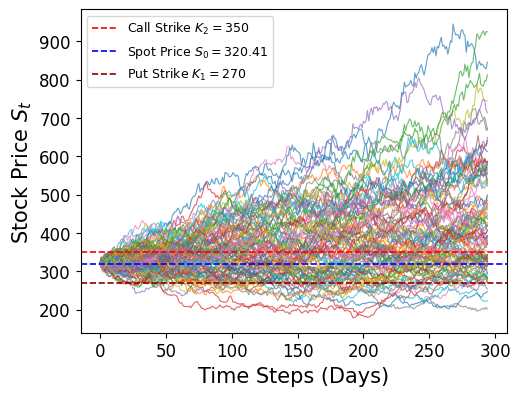

In [14]:
def plot_paths(levels, name, n_show=100):
    fig, ax = plt.subplots()
    ax.plot(paths[:n_show].T, lw=0.8, alpha=0.7)
    for value, label, color in levels:
        ax.axhline(value, color=color, ls="--", lw=1.2, label=label)
    ax.set_xlabel("Time Steps (Days)")
    ax.set_ylabel("Stock Price $S_t$")
    ax.legend(loc="upper left")
    save(fig, name)
    plt.show()

plot_paths([(K2, f"Call Strike $K_2 = {K2}$", "red"),
            (S0, f"Spot Price $S_0 = {S0}$", "blue"),
            (K1, f"Put Strike $K_1 = {K1}$", "darkred")], "pppn_simulated_paths")

In [15]:
premium = pppn_premium(ST, K1, K2)
E_premium = premium.mean()
se = premium.std(ddof=1) / np.sqrt(n_paths)

N = S0
E_payoff = 0.9 * N + E_premium

print(f"E[Premium]            = {E_premium:.2f}  (std. error {se:.2f})")
print(f"e^(-rT) E[Premium]    = {disc * E_premium:.2f}  vs. option cost {option_cost:.2f}")
print(f"P(premium > 0)        = {(premium > 0).mean():.1%}")
print(f"E[Payoff] = 0.9N + E[Premium] = {0.9 * N:.2f} + {E_premium:.2f} = {E_payoff:.2f}")
print(f"Expected growth factor E[Payoff]/N = {E_payoff / N:.3f}")

E[Premium]            = 95.57  (std. error 1.12)
e^(-rT) E[Premium]    = 91.60  vs. option cost 41.54
P(premium > 0)        = 76.9%
E[Payoff] = 0.9N + E[Premium] = 288.37 + 95.57 = 383.94
Expected growth factor E[Payoff]/N = 1.198


The discounted expected premium is far above what the two options cost. This does not mean the options are mispriced: the simulation uses JPM's historical drift, which is well above the risk-free rate.

## 3. Product 2: Airbag Note

### 3.1 Payoff

The Airbag Note has a participation rate $p\in(0,1)$ and an airbag level $A\in(0,S_0)$. At maturity it pays $N\varphi_{p,A}(S_T)$, where

$$
\varphi_{p,A}(S_T) =
\begin{cases}
1 + \dfrac{p}{S_0}(S_T - S_0), & S_T \ge S_0,\\[4pt]
1, & A \le S_T < S_0,\\[4pt]
\dfrac{S_T}{A}, & S_T < A,
\end{cases}
\qquad\Longleftrightarrow\qquad
\varphi_{p,A}(S_T) = 1 + \frac{p}{S_0}(S_T-S_0)^+ - \frac{1}{A}(A-S_T)^+ .
$$

We set the airbag at $A = 0.8\,S_0$.

In [16]:
def airbag_factor(ST, p, A, S0):
    return 1 + p / S0 * np.maximum(ST - S0, 0) - np.maximum(A - ST, 0) / A

A = 0.8 * S0
print(f"A = {A:.2f}")

A = 256.33


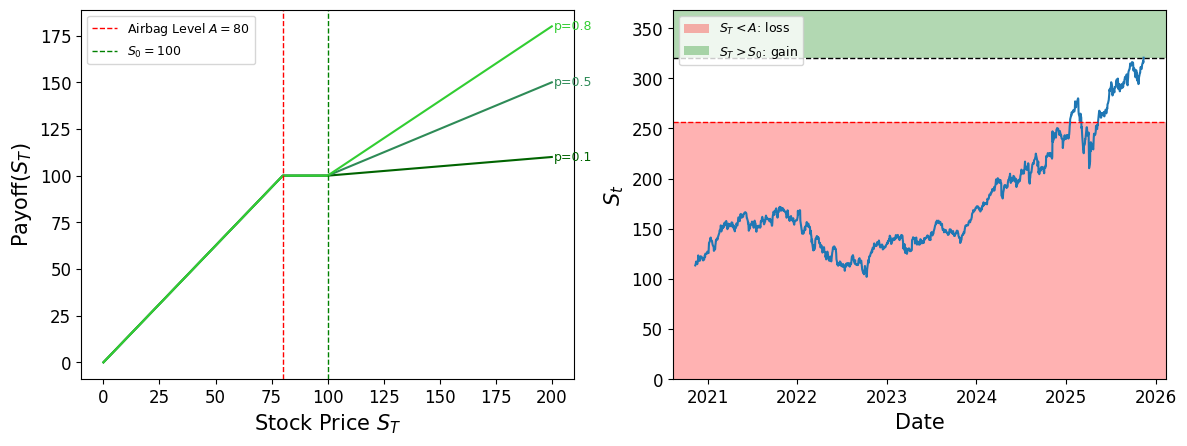

In [17]:
s = np.linspace(0, 200, 401)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

for p, c in [(0.1, "darkgreen"), (0.5, "seagreen"), (0.8, "limegreen")]:
    ax1.plot(s, 100 * airbag_factor(s, p, 80, 100), color=c)
    ax1.text(201, 100 * airbag_factor(200, p, 80, 100), f"p={p}", color=c, va="center", fontsize=9)
ax1.axvline(80, color="red", ls="--", lw=1, label="Airbag Level $A = 80$")
ax1.axvline(100, color="green", ls="--", lw=1, label="$S_0 = 100$")
ax1.set_xlabel("Stock Price $S_T$")
ax1.set_ylabel(r"Payoff$(S_T)$")
ax1.legend(loc="upper left")

top = 1.15 * prices.max()
shade(ax2, 0, A, "red", "$S_T < A$: loss")
shade(ax2, S0, top, "green", "$S_T > S_0$: gain")
ax2.plot(prices.index, prices.values)
ax2.axhline(S0, color="black", ls="--", lw=1)
ax2.axhline(A, color="red", ls="--", lw=1)
ax2.set_ylim(0, top)
ax2.set_xlabel("Date")
ax2.set_ylabel("$S_t$")
ax2.legend(loc="upper left")
save(fig, "airbag_payoff")
plt.show()

### 3.2 Replication and participation rate

The second form of $\varphi$ gives the replicating portfolio directly: a zero-coupon bond paying $N$, $Np/S_0$ long calls with strike $S_0$, and $N/A$ short puts with strike $A$. Adding the margin $mN$ and setting the total cost equal to $N$ gives

$$
1 = e^{-rT} + \frac{p}{S_0}EC(S_0,T) - \frac{1}{A}EP(A,T) + m .
$$

Both strikes are fixed, so solving for $p$ gives a linear function of the margin:

$$
p(m) = \underbrace{\Big(1 - e^{-rT} + \tfrac{1}{A}EP(A,T)\Big)\frac{S_0}{EC(S_0,T)}}_{\alpha} \;+\; m\,\underbrace{\Big(-\frac{S_0}{EC(S_0,T)}\Big)}_{\beta}.
$$

Neither $S_0 = 320.41$ nor $A = 256.33$ is a quoted strike. We therefore interpolate linearly between the two nearest quoted strikes.

In [18]:
EC_S0 = np.interp(S0, calls.index, calls.values)
EP_A = np.interp(A, puts.index, puts.values)

alpha = (1 - disc + EP_A / A) * S0 / EC_S0
beta = -S0 / EC_S0
participation = lambda m: alpha + beta * m

print(f"EC(S0) = {EC_S0:.2f}   (between EC(320) = {calls[320]:.2f} and EC(330) = {calls[330]:.2f})")
print(f"EP(A)  = {EP_A:.2f}   (between EP(250) = {puts[250]:.2f} and EP(260) = {puts[260]:.2f})")
print(f"alpha = {alpha:.4f}, beta = {beta:.4f}")
for m in (0, 0.005, 0.02):
    print(f"p({m:.1%}) = {participation(m):.3f}")

EC(S0) = 39.49   (between EC(320) = 39.71 and EC(330) = 34.40)
EP(A)  = 12.42   (between EP(250) = 12.55 and EP(260) = 12.35)
alpha = 0.7301, beta = -8.1132
p(0.0%) = 0.730
p(0.5%) = 0.690
p(2.0%) = 0.568


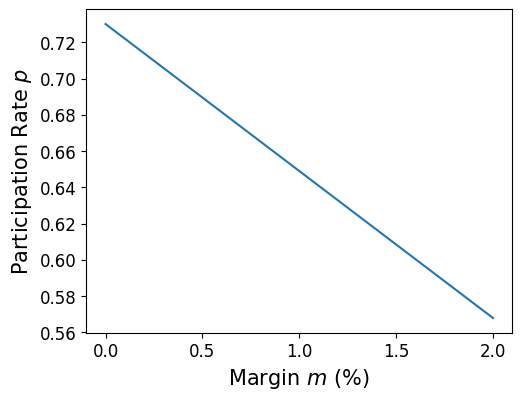

In [19]:
m_grid = np.linspace(0, 0.02, 101)
fig, ax = plt.subplots()
ax.plot(100 * m_grid, participation(m_grid))
ax.set_xlabel("Margin $m$ (%)")
ax.set_ylabel("Participation Rate $p$")
save(fig, "airbag_participation_vs_margin")
plt.show()

Here, too, we use a margin of $m = 0.5\%$.

### 3.3 Monte Carlo simulation

We reuse the simulated paths from Section 2.4 and evaluate the payoff factor on them.

In [20]:
m_airbag = 0.005
p = participation(m_airbag)

phi = airbag_factor(ST, p, A, S0)
print(f"p = {p:.3f}")
print(f"E[phi]          = {phi.mean():.3f}  (std. error {phi.std(ddof=1) / np.sqrt(n_paths):.3f})")
print(f"P(gain)         = {(ST > S0).mean():.1%}")
print(f"P(capital kept) = {((ST >= A) & (ST <= S0)).mean():.1%}")
print(f"P(loss)         = {(ST < A).mean():.1%}")

p = 0.690
E[phi]          = 1.234  (std. error 0.003)
P(gain)         = 76.4%
P(capital kept) = 16.2%
P(loss)         = 7.4%


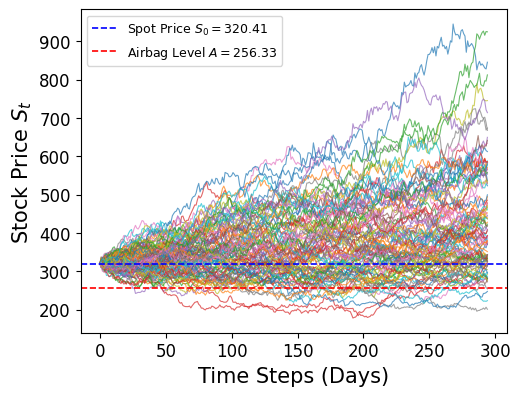

In [21]:
plot_paths([(S0, f"Spot Price $S_0 = {S0}$", "blue"),
            (A, f"Airbag Level $A = {A:.2f}$", "red")], "airbag_simulated_paths")

## 4. Summary

The table collects the main figures for both products. These are the numbers quoted in the report.

In [22]:
pd.DataFrame({
    "PPPN": {
        "Protection": "90% of N",
        "Options": f"long EP({K1}), long EC({K2})",
        "Key parameter": f"corridor [{K1}, {K2}]",
        "Margin m": f"{m_pppn:.1%}",
        "E[Payoff] / N": f"{E_payoff / N:.3f}",
    },
    "Airbag Note": {
        "Protection": f"100% of N while S_T >= {A:.2f}",
        "Options": f"long EC({S0}), short EP({A:.2f})",
        "Key parameter": f"participation p = {p:.3f}",
        "Margin m": f"{m_airbag:.1%}",
        "E[Payoff] / N": f"{phi.mean():.3f}",
    },
})

,PPPN,Airbag Note
Protection,90% of N,100% of N while S_T >= 256.33
Options,"long EP(270), long EC(350)","long EC(320.41), short EP(256.33)"
Key parameter,"corridor [270, 350]",participation p = 0.690
Margin m,0.5%,0.5%
E[Payoff] / N,1.198,1.234
